## 1_2 Two Layered Perceptron - Non-linear with ReLU AF (non-linear)

### Binary Classification


In [ ]:
%load_ext autoreload
%autoreload 2
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))
from gradient_descent import gradient_descent # my python file

import numpy as np
from sklearn.datasets import make_blobs
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap

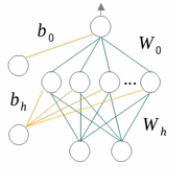

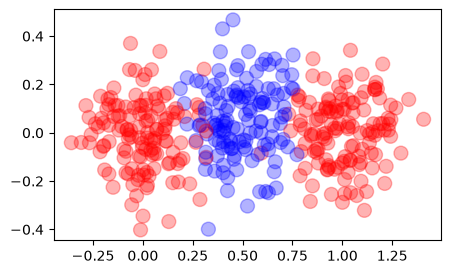

In [2]:
# Generate a dataset
x, y = make_blobs(n_samples=400, n_features=2,
                  centers=[[0., 0.], [0.5, 0.1], [1., 0.]],
                  cluster_std=0.15, center_box=(-1., 1.))

y[y == 2] = 0 # y = [0, 1, 2] -> [0, 1]
y = y.reshape(-1, 1)

# See the data visually.
plt.figure(figsize=(5,3))
color = [['red', 'blue'][a] for a in y.reshape(-1,)]
plt.scatter(x[:, 0], x[:, 1], s=100, c=color, alpha=0.3)
plt.show()

### Observation:

From above diagram we note that this is a binary classification problem, but a single line (SLP) cannot separate those classes so we need MLP to create a non-linear decision boundary to separate our data well.

In [3]:
# Generate the training and test data
x_train, x_test, y_train, y_test = train_test_split(x, y)

# Create an two-layered ANN model.
n_input = x.shape[1]  # the number of input neurons
n_output = 1          # the number of output neurons
n_hidden = 16         # the number of hidden neurons
alpha = 0.1           # learning rate

# initialize the parameters randomly.
wh = np.random.normal(size=(n_input, n_hidden))  # weights of hidden layer (2x16)
bh = np.zeros(shape=(1, n_hidden))               # biases of hidden layer (1x16)
wo = np.random.normal(size=(n_hidden, n_output)) # weights of output layer (16x1)
bo = np.zeros(shape=(1, n_output))               # bias of output layer(1x1)
parameters = [wh, bh, wo, bo]                    # parameter list

# activation functions
def sigmoid(x): return 1. / (1. + np.exp(-x))
def relu(x):    return np.maximum(0, x)

# loss function: binary cross entropy
def loss(y, y_hat):
    return -np.mean(y * np.log(y_hat) + (1. - y) * np.log(1. - y_hat))

0: train_loss=0.7830, val_loss=0.7957
10: train_loss=0.4732, val_loss=0.4925
20: train_loss=0.3657, val_loss=0.3942
30: train_loss=0.2918, val_loss=0.3273
40: train_loss=0.2457, val_loss=0.2956
50: train_loss=0.2172, val_loss=0.2606
60: train_loss=0.1943, val_loss=0.2438
70: train_loss=0.1785, val_loss=0.2251
80: train_loss=0.1652, val_loss=0.2249
90: train_loss=0.1552, val_loss=0.2157
100: train_loss=0.1477, val_loss=0.2056
110: train_loss=0.1404, val_loss=0.2014
120: train_loss=0.1351, val_loss=0.1886
130: train_loss=0.1299, val_loss=0.1881
140: train_loss=0.1277, val_loss=0.2027
150: train_loss=0.1224, val_loss=0.1832
160: train_loss=0.1200, val_loss=0.1775
170: train_loss=0.1170, val_loss=0.1674
180: train_loss=0.1152, val_loss=0.1840
190: train_loss=0.1130, val_loss=0.1818


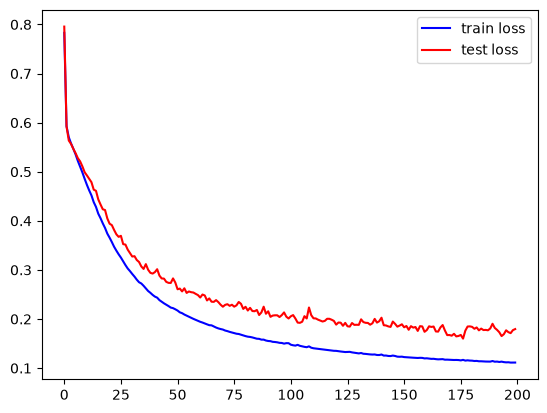

Accuracy of training data = 0.9600
Accuracy of test data = 0.9400


In [4]:
# Output from the ANN model: prediction process
def predict(x, proba=True):
    p = parameters
    h_out = relu(np.dot(x, p[0]) + p[1])        # output from hidden layer p_0: Wh; p_1: bh; p_2: wo; p_3: bo
    o_out = sigmoid(np.dot(h_out, p[2]) + p[3]) # output from output layer
    
    if proba:
        return o_out                            # return probability
    else:
        return (o_out > 0.5) * 1                # return class

# Perform training and track the loss history.
def train(x, y, x_val, y_val, epochs, batch_size):
    ht_loss = [] # loss history of training data
    hv_loss = [] # loss history of test data
    for epoch in range(epochs):
        # measure the losses during training
        # loss for training data
        ht_loss.append(loss(y, predict(x)))
        
        # loss for validation data
        hv_loss.append(loss(y_val, predict(x_val)))
        
        # Perform training using mini-batch gradient descent
        for batch in range(int(x.shape[0] / batch_size)):
            idx = np.random.choice(x.shape[0], batch_size)
            gradient_descent(x[idx], y[idx], alpha, loss, predict,
                             parameters)
            
        if epoch % 10 == 0:
            print("{}: train_loss={:.4f}, val_loss={:.4f}".\
                  format(epoch, ht_loss[-1], hv_loss[-1]))
            
    return ht_loss, hv_loss

# Perform training
train_loss, val_loss = train(x_train, y_train, x_test, y_test,
                             epochs=200, batch_size=50)

# Visually check the loss history.
plt.plot(train_loss, c='blue', label='train loss')
plt.plot(val_loss, c='red', label='test loss')
plt.legend()
plt.show()

# Check the accuracy.
y_pred = predict(x_train, proba=False)
acc = (y_pred == y_train).mean()
print("Accuracy of training data = {:.4f}".format(acc))

y_pred = predict(x_test, proba=False)
acc = (y_pred == y_test).mean()
print("Accuracy of test data = {:.4f}".format(acc))

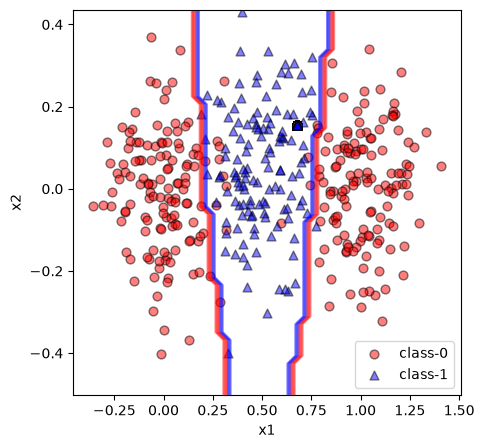

In [5]:
# Visualize the linear decision boundary
# reference : https://psrivasin.medium.com/
# plotting-decision-boundaries-using-numpy-and-matplotlib-
# f5613d8acd19
x_min, x_max = x_test[:, 0].min() - 0.1, x_test[:,0].max() + 0.1
y_min, y_max = x_test[:, 1].min() - 0.1, x_test[:, 1].max() + 0.1
xx, yy = np.meshgrid(np.linspace(x_min, x_max, 50),
                     np.linspace(y_min, y_max, 50))
x_in = np.c_[xx.ravel(), yy.ravel()]

# Predict the classes of the data points in the x_in variable.
y_pred = predict(x_in, proba=False).astype('int8')
y_pred = y_pred.reshape(xx.shape)

plt.figure(figsize=(5, 5))
m = ['o', '^']
color = ['red', 'blue']
for i in [0, 1]:
    idx = np.where(y == i)
    plt.scatter(x[idx, 0], x[idx, 1],
                c = color[i],
                marker = m[i],
                s = 40,
                edgecolor = 'black',
                alpha = 0.5,
                label='class-' + str(i))

plt.contour(xx, yy, y_pred, cmap=ListedColormap(color), alpha=0.5)
plt.axis('tight')
plt.xlim(xx.min(), xx.max())
plt.ylim(yy.min(), yy.max())
plt.xlabel('x1')
plt.ylabel('x2')
plt.legend()
plt.show()